<a href="https://colab.research.google.com/github/duong2006-hue/Kh-i/blob/main/smig_smog.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Loan Default Dataset

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("yasserh/loan-default-dataset")

print("Path to dataset files:", path)

Using Colab cache for faster access to the 'loan-default-dataset' dataset.
Path to dataset files: /kaggle/input/loan-default-dataset


In [ ]:
plt.rcParams["figure.figsize"] = (8, 4)
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False
BLUE = "#2a78d6"
ORANGE = "#eb6834"

---
# Stage 1 — Collect and check the data

In [ ]:
import os

df = pd.read_csv(os.path.join(path, "Loan_Default.csv"))
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])
df.head()

Rows: 148670
Columns: 34


,ID,year,loan_limit,Gender,approv_in_adv,loan_type,loan_purpose,Credit_Worthiness,open_credit,business_or_commercial,...,credit_type,Credit_Score,co-applicant_credit_type,age,submission_of_application,LTV,Region,Security_Type,Status,dtir1
0,24890,2019,cf,Sex Not Available,nopre,type1,p1,l1,nopc,nob/c,...,EXP,758,CIB,25-34,to_inst,98.728814,south,direct,1,45.0
1,24891,2019,cf,Male,nopre,type2,p1,l1,nopc,b/c,...,EQUI,552,EXP,55-64,to_inst,NaN,North,direct,1,NaN
2,24892,2019,cf,Male,pre,type1,p1,l1,nopc,nob/c,...,EXP,834,CIB,35-44,to_inst,80.019685,south,direct,0,46.0
3,24893,2019,cf,Male,nopre,type1,p4,l1,nopc,nob/c,...,EXP,587,CIB,45-54,not_inst,69.376900,North,direct,0,42.0
4,24894,2019,cf,Joint,pre,type1,p1,l1,nopc,nob/c,...,CRIF,602,EXP,25-34,not_inst,91.886544,North,direct,0,39.0


## Data types

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 148670 entries, 0 to 148669
Data columns (total 34 columns):
 #   Column                     Non-Null Count   Dtype  
---  ------                     --------------   -----  
 0   ID                         148670 non-null  int64  
 1   year                       148670 non-null  int64  
 2   loan_limit                 145326 non-null  object 
 3   Gender                     148670 non-null  object 
 4   approv_in_adv              147762 non-null  object 
 5   loan_type                  148670 non-null  object 
 6   loan_purpose               148536 non-null  object 
 7   Credit_Worthiness          148670 non-null  object 
 8   open_credit                148670 non-null  object 
 9   business_or_commercial     148670 non-null  object 
 10  loan_amount                148670 non-null  int64  
 11  rate_of_interest           112231 non-null  float64
 12  Interest_rate_spread       112031 non-null  float64
 13  Upfront_charges            10

In [ ]:
print(df["Status"].value_counts())
print("Default rate:", round(df["Status"].mean() * 100, 1), "%")

Status
0    112031
1     36639
Name: count, dtype: int64
Default rate: 24.6 %


## Missing values

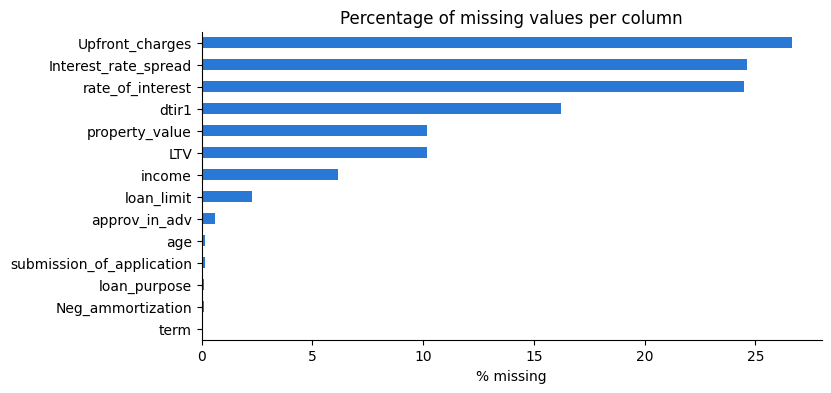

Upfront_charges              26.7
Interest_rate_spread         24.6
rate_of_interest             24.5
dtir1                        16.2
property_value               10.2
LTV                          10.2
income                        6.2
loan_limit                    2.2
approv_in_adv                 0.6
Neg_ammortization             0.1
loan_purpose                  0.1
age                           0.1
submission_of_application     0.1
term                          0.0
dtype: float64


In [ ]:
missing = df.isnull().mean() * 100
missing = missing[missing > 0].sort_values()

missing.plot(kind="barh", color=BLUE)
plt.title("Percentage of missing values per column")
plt.xlabel("% missing")
plt.show()

print(missing.round(1).sort_values(ascending=False))

## Duplicates and consistency

In [ ]:
print("Duplicate rows:", df.duplicated().sum())
print("Duplicate IDs:", df["ID"].duplicated().sum())
print("Values in 'year':", df["year"].unique())
print("Values in 'Region':", df["Region"].unique())
print("Values in 'Security_Type':", df["Security_Type"].unique())

Duplicate rows: 0
Duplicate IDs: 0
Values in 'year': [2019]
Values in 'Region': ['south' 'North' 'central' 'North-East']
Values in 'Security_Type': ['direct' 'Indriect']


In [ ]:
# Do these two columns say the same thing?
pd.crosstab(df["loan_type"], df["business_or_commercial"])

business_or_commercial,b/c,nob/c
loan_type,,
type1,0,113173
type2,20762,0
type3,0,14735


In [ ]:
clean = df.copy()

# Fix capital letters and the typo
clean["Region"] = clean["Region"].str.title()
clean["Security_Type"] = clean["Security_Type"].replace("Indriect", "Indirect")

# Remove columns that give no useful information
clean = clean.drop(columns=["ID", "year", "business_or_commercial"])

print(clean["Region"].unique())
print("Columns left:", clean.shape[1])

['South' 'North' 'Central' 'North-East']
Columns left: 31


## Missing values

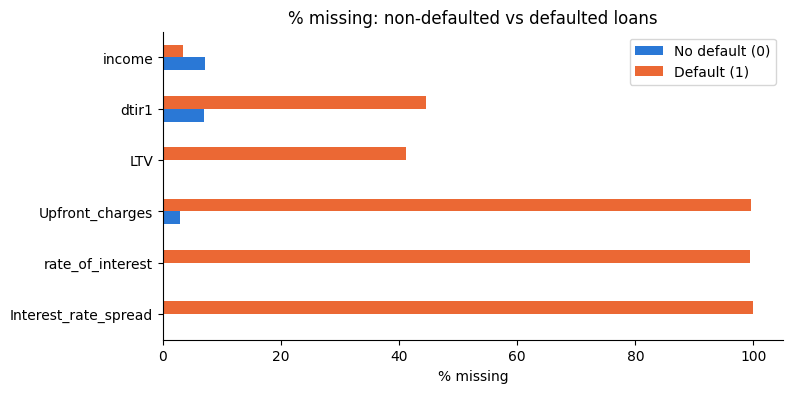

,No default (0),Default (1)
Interest_rate_spread,0.0,100.0
rate_of_interest,0.0,99.5
Upfront_charges,2.8,99.6
LTV,0.0,41.2
dtir1,7.0,44.5
income,7.1,3.4


In [ ]:
cols = ["Interest_rate_spread", "rate_of_interest", "Upfront_charges", "LTV", "dtir1", "income"]
missing_by_status = clean.groupby("Status")[cols].apply(lambda x: x.isnull().mean() * 100).T
missing_by_status.columns = ["No default (0)", "Default (1)"]

missing_by_status.plot(kind="barh", color=[BLUE, ORANGE])
plt.title("% missing: non-defaulted vs defaulted loans")
plt.xlabel("% missing")
plt.show()

missing_by_status.round(1)

In [ ]:
guess = clean["Interest_rate_spread"].isnull().astype(int)
accuracy = (guess == clean["Status"]).mean()
print("Accuracy of guessing with only one empty field:", round(accuracy * 100, 2), "%")

Accuracy of guessing with only one empty field: 100.0 %


In [ ]:
clean.groupby("credit_type")["Status"].mean().round(3) * 100

,Status
credit_type,
CIB,15.8
CRIF,16.2
EQUI,100.0
EXP,16.0


In [ ]:
clean = clean.drop(columns=["Interest_rate_spread", "rate_of_interest", "Upfront_charges", "credit_type"])
clean = clean.dropna(subset=["LTV"])

print("Rows left:", len(clean))
print("Default rate now:", round(clean["Status"].mean() * 100, 1), "%")

Rows left: 133572
Default rate now: 16.1 %


## Fill in the remaining missing values

In [ ]:
print(clean.isnull().sum()[clean.isnull().sum() > 0])

loan_limit                   2977
approv_in_adv                 811
loan_purpose                  117
term                           29
Neg_ammortization             113
income                       9135
age                           200
submission_of_application     200
dtir1                        9025
dtype: int64


In [ ]:
clean.loc[clean["income"] == 0, "income"] = np.nan

print("Mean income:  ", round(clean["income"].mean()))
print("Median income:", round(clean["income"].median()))
print("Max income:   ", round(clean["income"].max()))

Mean income:   7033
Median income: 5820
Max income:    578580


In [ ]:
for col in ["income", "dtir1", "term"]:
    clean[col] = clean[col].fillna(clean[col].median())

for col in ["loan_limit", "approv_in_adv", "loan_purpose", "Neg_ammortization", "age", "submission_of_application"]:
    clean[col] = clean[col].fillna(clean[col].mode()[0])

print("Missing values left:", clean.isnull().sum().sum())

Missing values left: 0


##Outliers

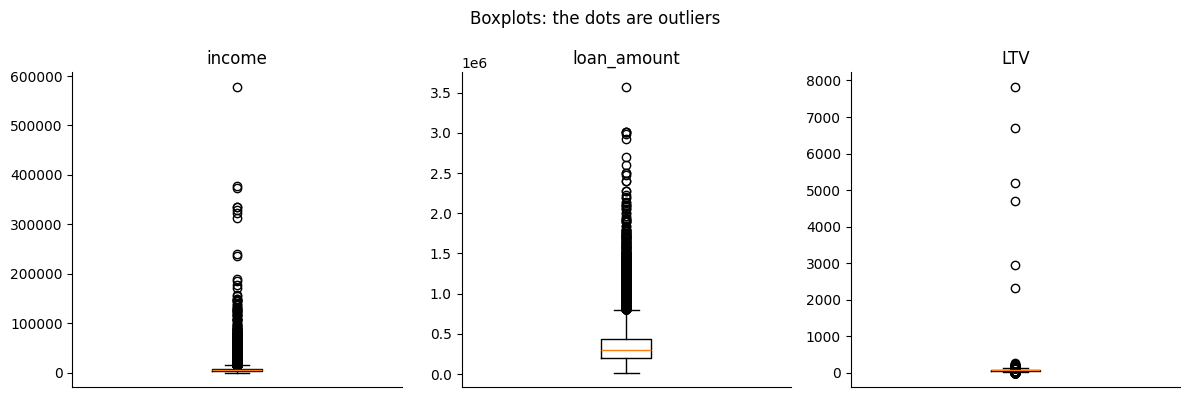

         income  loan_amount       LTV
count  133572.0     133572.0  133572.0
mean     6946.8     331256.1      72.7
std      6279.6     181750.4      40.0
min        60.0      16500.0       1.0
25%      3960.0     196500.0      60.5
50%      5820.0     296500.0      75.1
75%      8280.0     436500.0      86.2
max    578580.0    3576500.0    7831.2


In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(12, 4))
for ax, col in zip(axes, ["income", "loan_amount", "LTV"]):
    ax.boxplot(clean[col])
    ax.set_title(col)
    ax.set_xticks([])
plt.suptitle("Boxplots: the dots are outliers")
plt.tight_layout()
plt.show()

print(clean[["income", "loan_amount", "LTV"]].describe().round(1))

In [ ]:
cap = clean["LTV"].quantile(0.999)
print("LTV cap:", round(cap, 1), "%")
print("Rows capped:", (clean["LTV"] > cap).sum())
clean["LTV"] = clean["LTV"].clip(upper=cap)

LTV cap: 123.7 %
Rows capped: 133


## Encoding and scaling


In [ ]:
model_data = clean.copy()

age_order = {"<25": 0, "25-34": 1, "35-44": 2, "45-54": 3, "55-64": 4, "65-74": 5, ">74": 6}
model_data["age"] = model_data["age"].map(age_order)
model_data["total_units"] = model_data["total_units"].str.replace("U", "").astype(int)

model_data = pd.get_dummies(model_data, drop_first=True, dtype=int)
print("Shape after encoding:", model_data.shape)

Shape after encoding: (133572, 35)


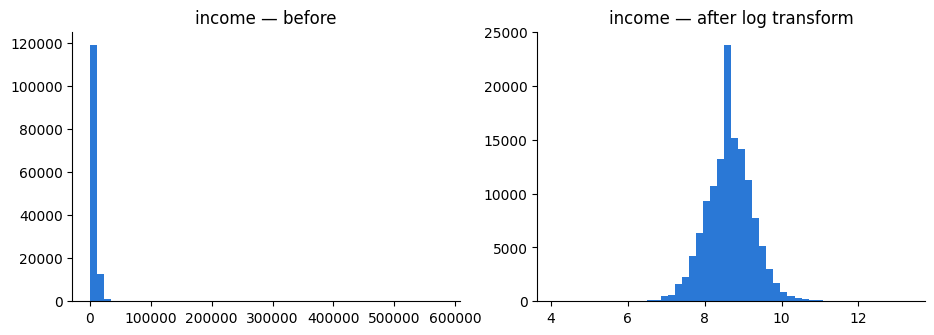

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
axes[0].hist(model_data["income"], bins=50, color=BLUE)
axes[0].set_title("income — before")

for col in ["income", "loan_amount", "property_value"]:
    model_data[col] = np.log1p(model_data[col])

axes[1].hist(model_data["income"], bins=50, color=BLUE)
axes[1].set_title("income — after log transform")
plt.show()

In [ ]:
from sklearn.preprocessing import StandardScaler

num_cols = ["loan_amount", "income", "property_value", "LTV", "dtir1", "term", "Credit_Score"]
model_data[num_cols] = StandardScaler().fit_transform(model_data[num_cols])
model_data[num_cols].describe().loc[["mean", "std"]].round(2)

,loan_amount,income,property_value,LTV,dtir1,term,Credit_Score
mean,-0.0,-0.0,-0.0,0.0,0.0,0.0,0.0
std,1.0,1.0,1.0,1.0,1.0,1.0,1.0


---
# Stage 3 — Analyse and visualise
| | Hypothesis |
|---|---|
| H1 | Older borrowers default more |
| H2 | Borrowers with lower income default more |
| H3 | Borrowers with a higher LTV (less of the house paid for) default more |
| H4 | Borrowers with a higher debt-to-income ratio default more |
| H5 | Borrowers with a lower credit score default more |
| H6 | Risky loan types (lump-sum payment, negative amortisation) default more |

In [ ]:
average = clean["Status"].mean() * 100

def plot_default_rate(column, title):
    rate = clean.groupby(column, observed=True)["Status"].mean() * 100
    ax = rate.plot(kind="bar", color=BLUE, rot=0)
    ax.bar_label(ax.containers[0], fmt="%.1f%%")
    avg_line = ax.axhline(average, color="gray", linestyle="--", label=f"average {average:.1f}%")
    ax.set_ylabel("Default rate (%)")
    ax.set_title(title)
    ax.legend(handles=[avg_line])
    plt.show()

## H1 — Age

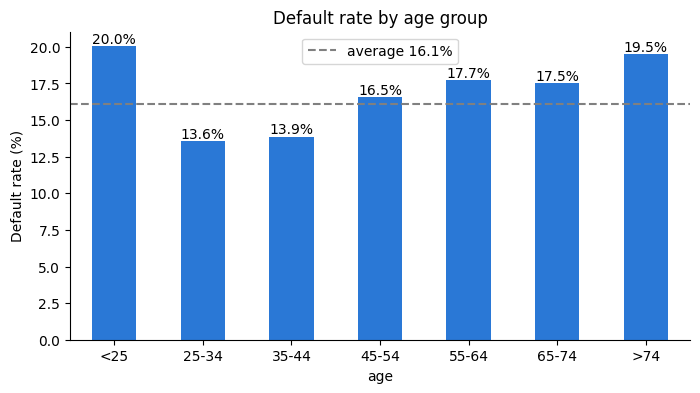

In [ ]:
clean["age"] = pd.Categorical(clean["age"], ["<25", "25-34", "35-44", "45-54", "55-64", "65-74", ">74"], ordered=True)
plot_default_rate("age", "Default rate by age group")


## H2 — Income

income_group
Very low      2700.0
Low           4380.0
Middle        5820.0
High          7620.0
Very high    11940.0
Name: income, dtype: float64


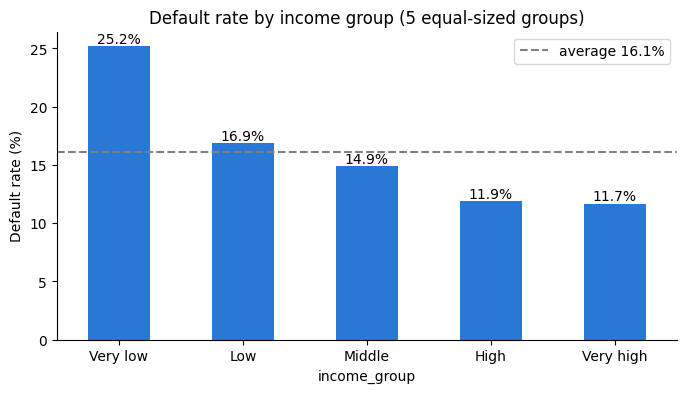

In [ ]:
clean["income_group"] = pd.qcut(clean["income"], 5, labels=["Very low", "Low", "Middle", "High", "Very high"])
print(clean.groupby("income_group", observed=True)["income"].median())
plot_default_rate("income_group", "Default rate by income group (5 equal-sized groups)")


## H3 — Loan-to-value (LTV)

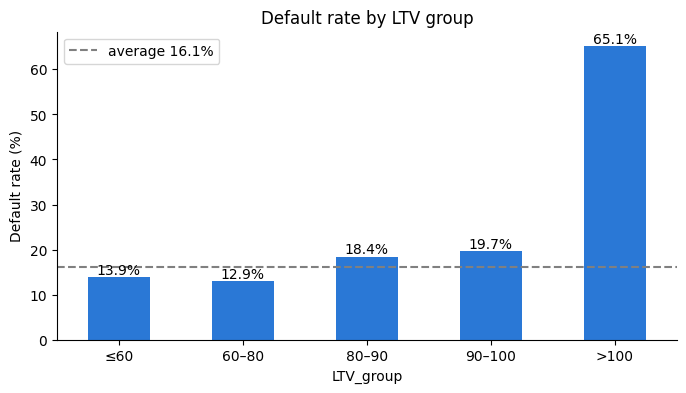

In [ ]:
clean["LTV_group"] = pd.cut(clean["LTV"], bins=[0, 60, 80, 90, 100, 200],
                            labels=["≤60", "60–80", "80–90", "90–100", ">100"])
plot_default_rate("LTV_group", "Default rate by LTV group")


## H4 — Debt-to-income (DTI)

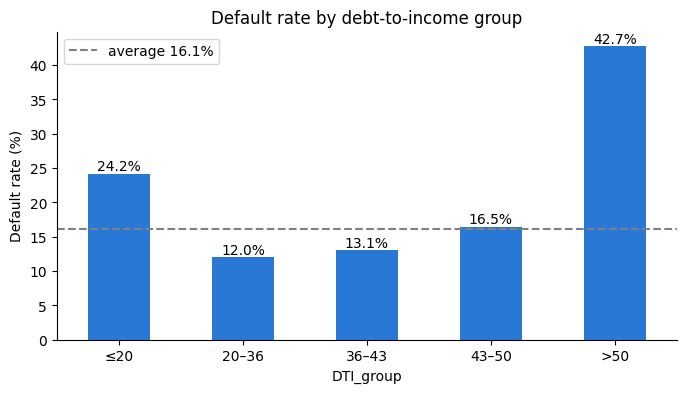

In [ ]:
clean["DTI_group"] = pd.cut(clean["dtir1"], bins=[0, 20, 36, 43, 50, 61],
                            labels=["≤20", "20–36", "36–43", "43–50", ">50"])
plot_default_rate("DTI_group", "Default rate by debt-to-income group")


## H5 — Credit score

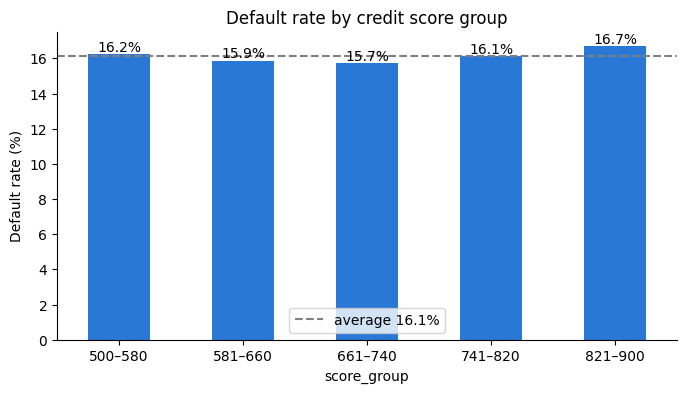

In [ ]:
clean["score_group"] = pd.cut(clean["Credit_Score"], bins=[499, 580, 660, 740, 820, 900],
                              labels=["500–580", "581–660", "661–740", "741–820", "821–900"])
plot_default_rate("score_group", "Default rate by credit score group")

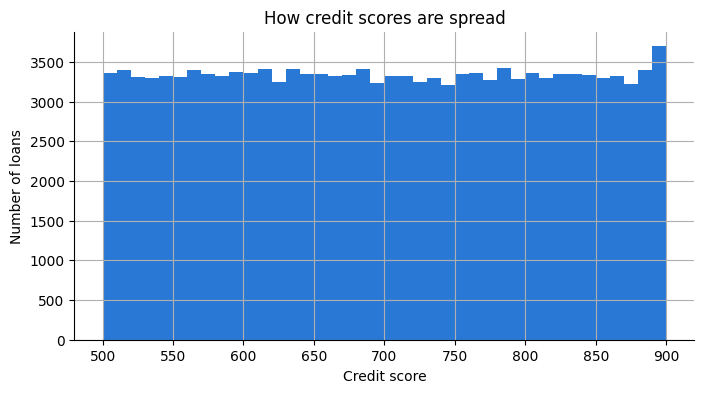

In [ ]:
clean["Credit_Score"].hist(bins=40, color=BLUE)
plt.title("How credit scores are spread")
plt.xlabel("Credit score")
plt.ylabel("Number of loans")
plt.show()


## H6 — Risky loan types

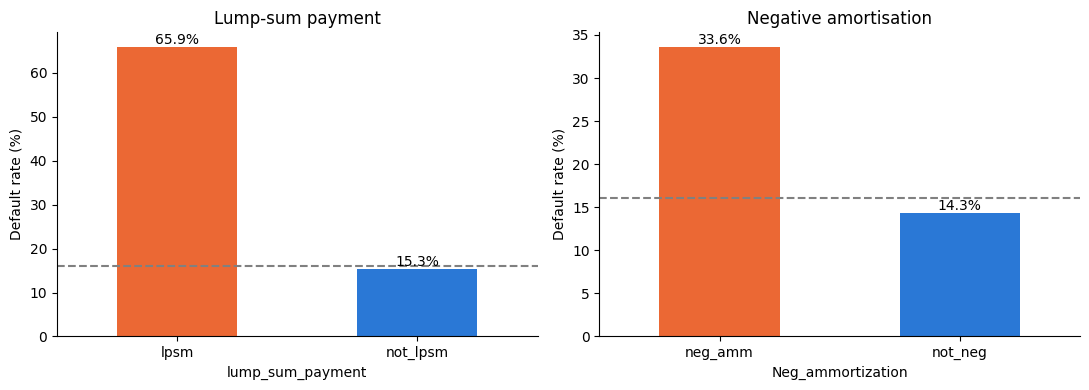

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, col, title in [(axes[0], "lump_sum_payment", "Lump-sum payment"),
                       (axes[1], "Neg_ammortization", "Negative amortisation")]:
    rate = clean.groupby(col)["Status"].mean() * 100
    rate.plot(kind="bar", color=[ORANGE, BLUE], rot=0, ax=ax)
    ax.bar_label(ax.containers[0], fmt="%.1f%%")
    ax.axhline(average, color="gray", linestyle="--")
    ax.set_title(title)
    ax.set_ylabel("Default rate (%)")
plt.tight_layout()
plt.show()

## Correlation heatmap

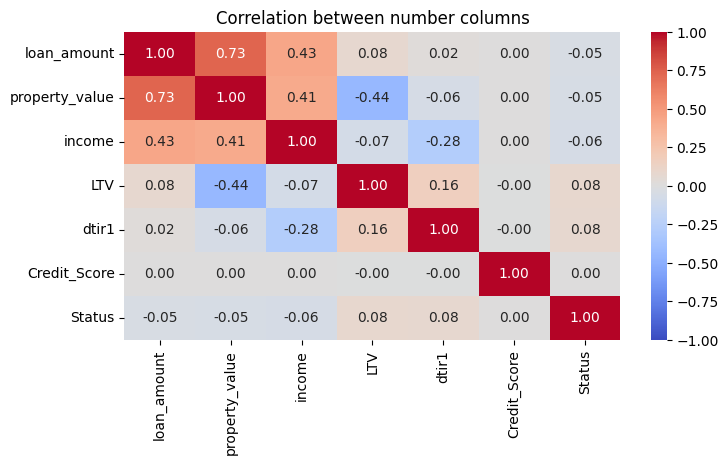

In [ ]:
num = ["loan_amount", "property_value", "income", "LTV", "dtir1", "Credit_Score", "Status"]
sns.heatmap(clean[num].corr(), annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Correlation between number columns")
plt.show()


## Hypothesis results

In [ ]:
results = pd.DataFrame({
    "Hypothesis": ["H1 Age", "H2 Income", "H3 LTV", "H4 DTI", "H5 Credit score", "H6 Risky loan types"],
    "Result": ["Partly true", "True", "Strongly true", "True (above 43%)", "False", "Strongly true"],
    "Key number": ["13.6% → 19.5%", "25.2% → ~12%", "~13% → 65.1%", "42.7% when DTI > 50%",
                   "flat, 15.7–16.7%", "lump sum 65.9%, neg. amort. 33.6%"],
})
results

,Hypothesis,Result,Key number
0,H1 Age,Partly true,13.6% → 19.5%
1,H2 Income,True,25.2% → ~12%
2,H3 LTV,Strongly true,~13% → 65.1%
3,H4 DTI,True (above 43%),42.7% when DTI > 50%
4,H5 Credit score,False,"flat, 15.7–16.7%"
5,H6 Risky loan types,Strongly true,"lump sum 65.9%, neg. amort. 33.6%"


---
# Stage 4 — Conclusions and recommendations

## Main findings

1. **Some columns leaked the answer.** `Interest_rate_spread` was empty for every defaulted loan, so a single empty field predicted default with 100% accuracy. We removed these columns. Without this cleaning step, any model would look perfect but be useless.
2. **LTV is the strongest warning sign.** Loans bigger than the house value default 65% of the time.
3. **Risky loan types are very dangerous.** Lump-sum payment loans default 66% of the time and negative-amortisation loans 34%, compared with about 15% for normal loans.
4. **High debt and low income increase risk.** Borrowers with DTI above 50% default 43% of the time, and the lowest-income group 25%.
5. **The credit score in this dataset is not useful**, because it seems to be random numbers.

## Recommendations (for a bank)

* Be careful with loans where **LTV is above 90%**, and avoid loans above 100%. Ask for a bigger down payment or mortgage insurance.
* Set a **maximum DTI of about 43–50%**.
* Offer **lump-sum and negative-amortisation loans** only to borrowers who can clearly afford the large later payment.
* **Check the information on applications.** Very low DTI values were linked to higher risk, so suspicious numbers should be verified.
* **Fix data collection.** Fields like the interest rate should be recorded for *all* loans, not only for loans that went well.

## Limitations of the data

* There is **no official description** of the columns, so the meanings of codes like `p1`–`p4` and `type1`–`type3` are unknown.
* We removed 15,098 incomplete rows, which were mostly defaults, so our default rate (16.1%) is lower than in the full data (24.6%).
* `Credit_Score` looks fake, and other columns may also have been changed.
* The data covers **only one year (2019)**, so we cannot see changes over time.
* We found **relationships, not causes**. For example, risky loan types may attract riskier borrowers rather than cause default themselves.

## Future work

* Get the official column descriptions from the data owner.
* Build a prediction model (e.g. logistic regression or a decision tree) on the cleaned data, `model_data`.
* Get data from more years to check if the patterns stay the same.